In [1]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
from pathlib import Path
import os


def save_fig(name):
    plt.savefig(os.path.join("../Data", name), dpi=300, bbox_inches='tight')

# Реализуйте высокочастотную фильтрацию на основе ядра Гаусса

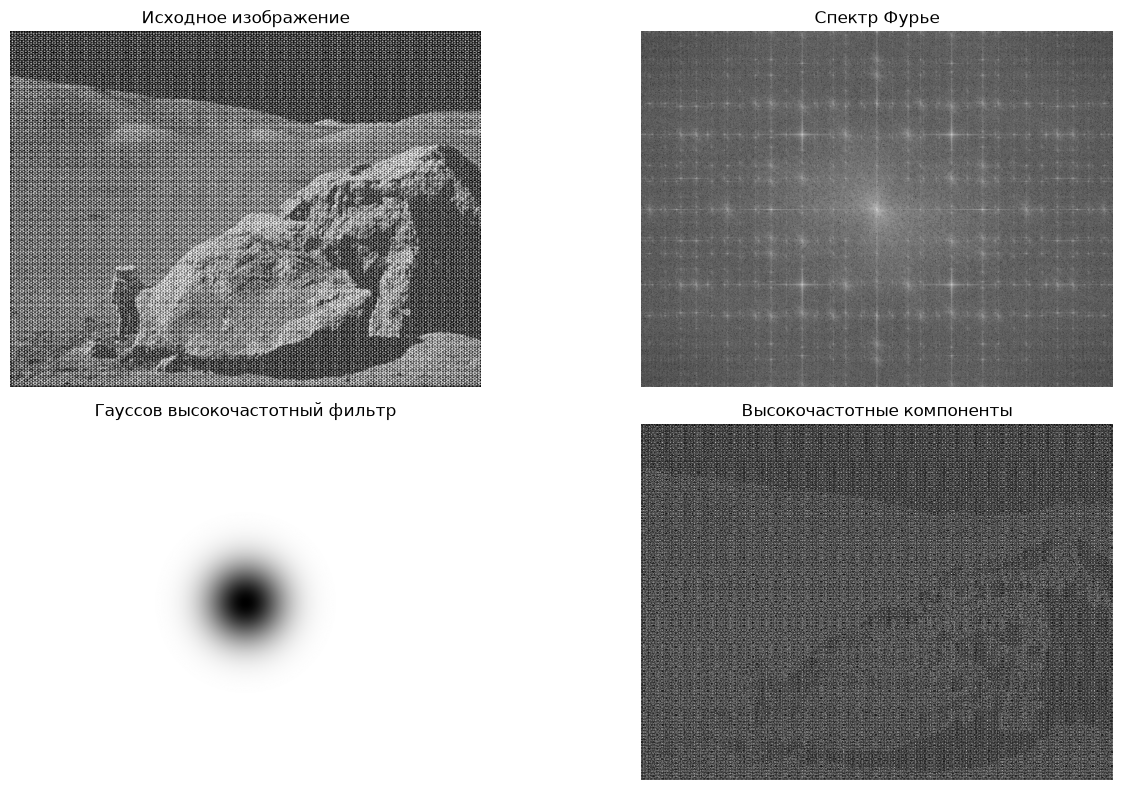

In [2]:
image_path = Path('periodic_noise.JPG')
image_gray = cv.imread(str(image_path), cv.IMREAD_GRAYSCALE)

image_float = image_gray.astype(np.float32)
height, width = image_gray.shape

spectrum = np.fft.fft2(image_float)
spectrum = np.fft.fftshift(spectrum)
log_spectrum = np.log1p(np.abs(spectrum))

sigma_hp = 45
cy = height // 2
cx = width // 2
y, x = np.ogrid[:height, :width]
radius_sq = (y - cy) ** 2 + (x - cx) ** 2
highpass_mask = 1.0 - np.exp(-radius_sq / (2.0 * sigma_hp ** 2))

highpass_fft = spectrum * highpass_mask
highpass_spatial = np.fft.ifft2(np.fft.ifftshift(highpass_fft)).real
highpass_display = cv.normalize(
    np.abs(highpass_spatial), None, 0, 255, cv.NORM_MINMAX
).astype(np.uint8)

plt.figure(figsize=(14, 8))

plt.subplot(2, 2, 1)
plt.imshow(image_gray, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(log_spectrum, cmap='gray')
plt.title('Спектр Фурье')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(highpass_mask, cmap='gray', vmin=0, vmax=1)
plt.title('Гауссов высокочастотный фильтр')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(highpass_display, cmap='gray')
plt.title('Высокочастотные компоненты')
plt.axis('off')

plt.tight_layout()
save_fig("L5_highpass.png")
plt.show()


# Реализуйте вычисление свертки с помощью преобразования Фурье

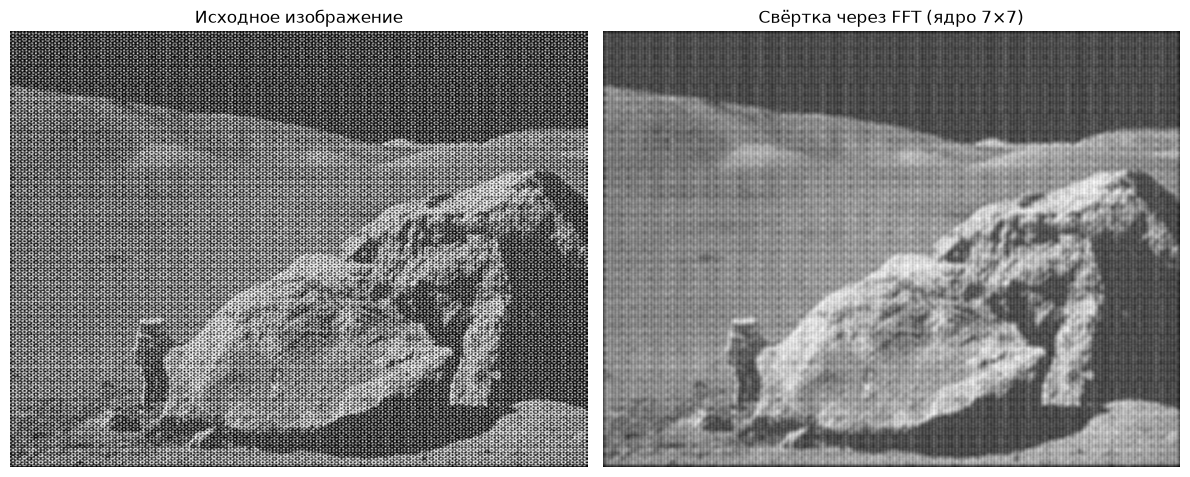

In [3]:
kernel = np.ones((7, 7), dtype=np.float32) / 49.0
kh, kw = kernel.shape

fft_shape = (height + kh - 1, width + kw - 1)

image_fft = np.fft.fft2(image_float, s=fft_shape)
kernel_fft = np.fft.fft2(kernel, s=fft_shape)
result_fft = image_fft * kernel_fft
result = np.fft.ifft2(result_fft).real

conv_fft = result[
    kh // 2 : kh // 2 + height,
    kw // 2 : kw // 2 + width
]

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_gray, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(conv_fft, cmap='gray')
plt.title('Свёртка через FFT (ядро 7×7)')
plt.axis('off')

plt.tight_layout()
save_fig("L5_conv_fft.png")
plt.show()


# Реализуйте удаление периодического шума с помощью преобразования Фурье

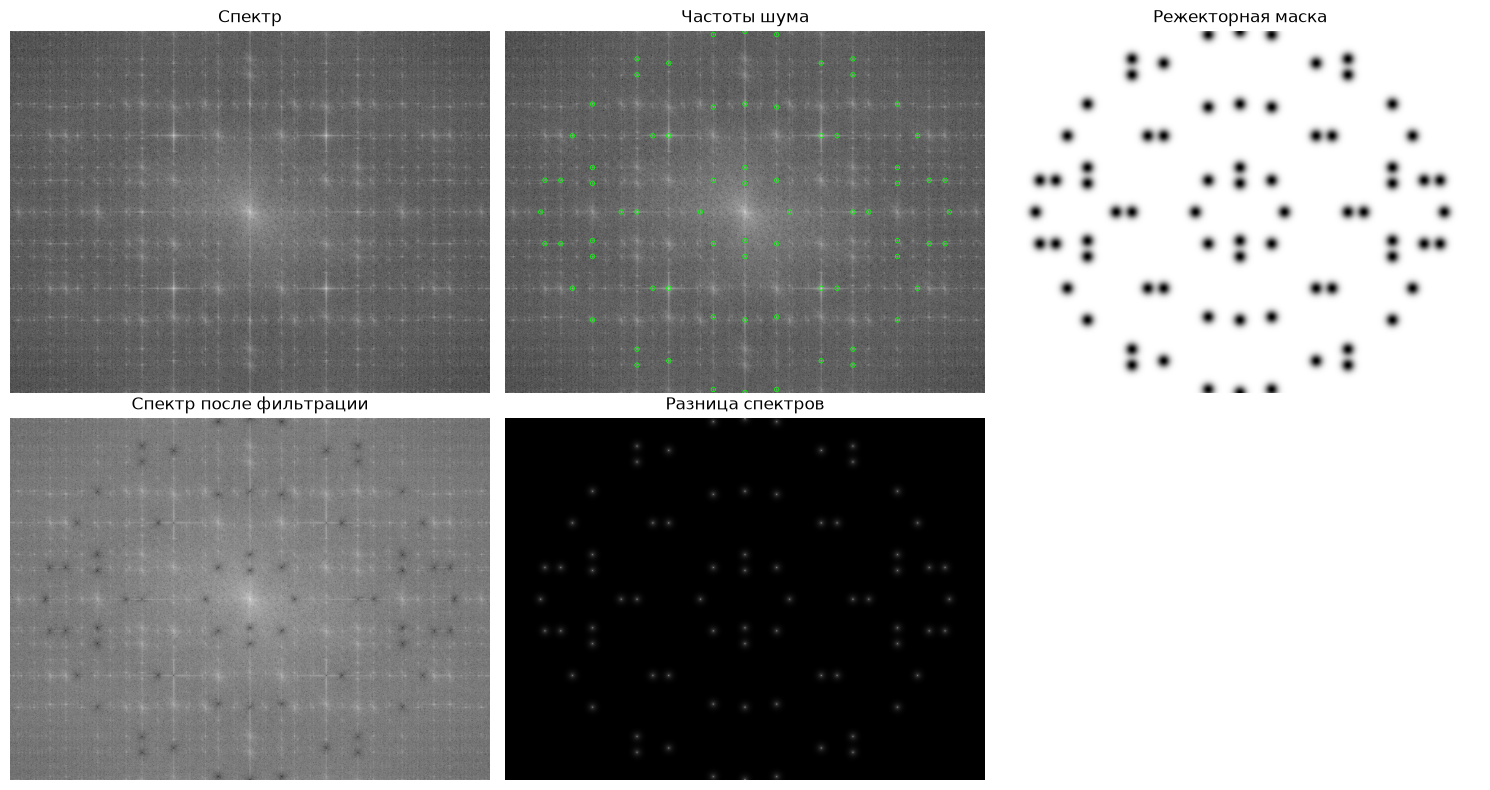

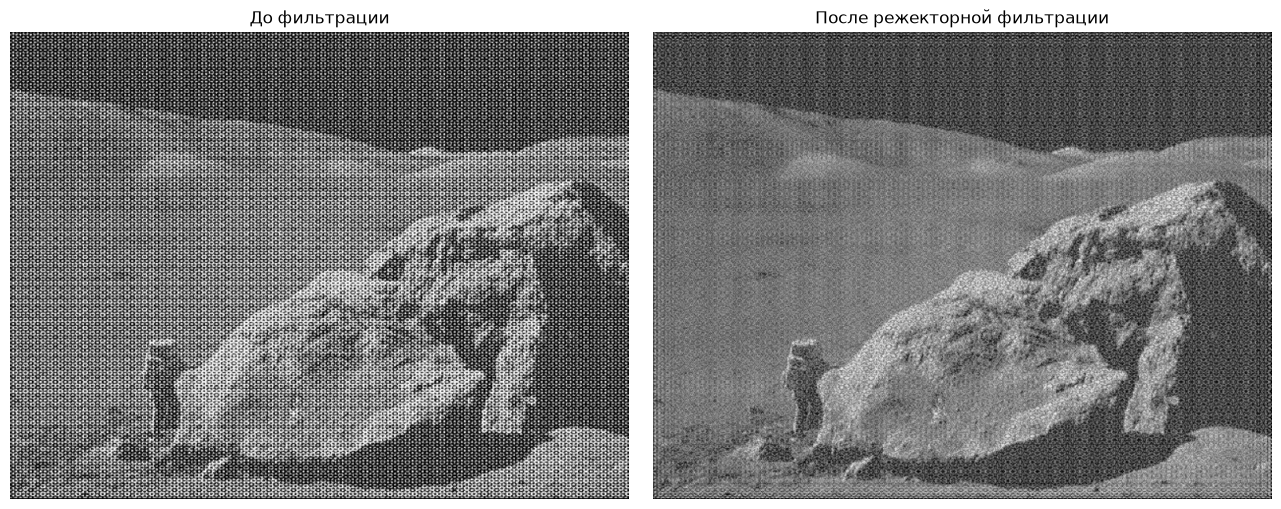

In [4]:
spectral_background = cv.GaussianBlur(log_spectrum.astype(np.float32), (0, 0), 12)
spectral_contrast = log_spectrum - spectral_background

local_max = cv.dilate(spectral_contrast, np.ones((11, 11), np.uint8))
peak_threshold = 3.8
center_radius = 30

peak_map = (
    (spectral_contrast >= local_max - 1e-6)
    & (spectral_contrast > peak_threshold)
    & (radius_sq > center_radius ** 2)
)

detected_peaks = np.column_stack(np.where(peak_map))

if len(detected_peaks) == 0:
    raise RuntimeError('Частотные пики не найдены')

mirror_peaks = np.column_stack(
    ((2 * cy - detected_peaks[:, 0]) % height,
     (2 * cx - detected_peaks[:, 1]) % width)
)

peak_positions = np.unique(np.vstack([detected_peaks, mirror_peaks]), axis=0)

sigma_notch = 7.0
notch_mask = np.ones((height, width), dtype=np.float32)

for py, px in peak_positions:
    distance_sq = (y - py) ** 2 + (x - px) ** 2
    gaussian_notch = 1.0 - np.exp(-distance_sq / (2.0 * sigma_notch ** 2))
    notch_mask *= gaussian_notch.astype(np.float32)

filtered_spectrum = spectrum * notch_mask
restored = np.fft.ifft2(np.fft.ifftshift(filtered_spectrum)).real
denoised_image = np.clip(restored, 0, 255).astype(np.uint8)
filtered_log_spectrum = np.log1p(np.abs(filtered_spectrum))

plt.figure(figsize=(15, 8))

plt.subplot(2, 3, 1)
plt.imshow(log_spectrum, cmap='gray')
plt.title('Спектр')
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(log_spectrum, cmap='gray')
plt.scatter(
    peak_positions[:, 1],
    peak_positions[:, 0],
    s=10,
    facecolors='none',
    edgecolors='lime',
    linewidths=0.6
)
plt.title('Частоты шума')
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(notch_mask, cmap='gray', vmin=0, vmax=1)
plt.title('Режекторная маска')
plt.axis('off')

plt.subplot(2, 3, 4)
plt.imshow(filtered_log_spectrum, cmap='gray')
plt.title('Спектр после фильтрации')
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(np.abs(log_spectrum - filtered_log_spectrum), cmap='gray')
plt.title('Разница спектров')
plt.axis('off')

plt.tight_layout()
save_fig("L5_notch_filter.png")
plt.show()


plt.figure(figsize=(13, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_gray, cmap='gray', vmin=0, vmax=255)
plt.title('До фильтрации')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(denoised_image, cmap='gray', vmin=0, vmax=255)
plt.title('После режекторной фильтрации')
plt.axis('off')

plt.tight_layout()
save_fig("L5_before_after.png")
plt.show()